## A noise model for the compiled DB-DOI circuits

All earlier circuit-level results are noiseless. Here every CNOT of the compiled circuits is followed by a two-qubit depolarizing channel of strength $p$, $\rho \mapsto (1-p)\rho + p\,\mathrm{Tr}_{ab}(\rho)\otimes I_{ab}/4$ on its two qubits $a, b$ (the convention of qibo's `DepolarizingChannel`); single-qubit gates are noiseless. Circuits (4 qubits each):
- Model 1 (Ce:YAG): DB-DOI of `Example_3` (durations $\le 0.3$, 4 second-order Trotter steps per oracle call, 2 152 CNOTs);
- Model 1 with the extended duration grid of `Example_12` (durations up to $10^2$), with an oracle accurate to $5\times10^{-3}$ at the longest evolution, so that the net cost of longer durations (fewer oracle calls, more Trotter steps per call) is explicit;
- the two-stage DB-DOI of `Example_14` in the Z1 block of Model 3 and the $^4I_{15/2}$ block of Model 2.

**Method.** The circuits reach $3\times10^6$ CNOTs, too many to build as noisy qibo circuits in memory (a first attempt exhausted 24 GB). Instead each noisy oracle call is a $256\times256$ superoperator: one Trotter step is applied gate by gate, with the channel after every CNOT, to all 256 matrix units, and the call is its $n$-th power. The DB-DOI recursion of `GroupCommutatorIteration` is then composed from these superoperators in the order of the circuit: step $k$ applies $e^{-i\sqrt{s}D}$, the previous circuit, the oracle, the inverse previous circuit, $e^{i\sqrt{s}D}$, and the previous circuit again. In a noisy circuit the inverse of a sub-circuit is a different channel, so it is tracked separately; the inverse of a symmetric second-order Trotter call is the call with $-t$ and the same CNOTs. The depolarizing channel is applied as a Pauli twirl, $\mathrm{Tr}_{ab}(\rho)\otimes I/4 = \frac1{16}\sum_{P} P\rho P$ over the 16 two-qubit Paulis. The first cells check the method against qibo's own noisy density-matrix simulation of the explicit circuits.

Results are compared with the global-depolarizing estimate $F \approx F_0 (1-p)^N + (1-(1-p)^N)\,g/16$ ($N$ CNOTs, $g$ the target degeneracy, $F_0$ the noiseless fidelity), which then bounds the error rates the full 8- and 9-qubit circuits would need. The notebook takes about 20 minutes.

In [1]:
import os

os.environ["OPENBLAS_NUM_THREADS"] = "2"

import logging
import pickle
import sys
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

from qibo import Circuit, gates, hamiltonians, set_backend
from qibo.backends import NumpyBackend
from qibo.config import log
from qibo.noise import DepolarizingError, NoiseModel
from qibo.symbols import Z

from pycf.import_sljm import ImportSLJM

from qibo_dbqa.utils_crystal_field import *

sys.path.append(os.path.abspath("../../src"))
from db_doi.group_commutator_iteration import GroupCommutatorIteration, DoubleBracketRotationApproximationType

os.environ.setdefault("PYCF_ROOT", os.path.abspath("../../../pycf"))
set_backend("numpy")
log.setLevel(logging.ERROR)
os.makedirs("pdfs_figures", exist_ok=True)
BACKEND = NumpyBackend()
N = 4
DIM = 2**N
P_VALUES = (0.0, 1e-5, 1e-4, 1e-3, 1e-2)
PAULIS = [PAULI_MATRICES[c] for c in "IXYZ"]


def gate_list(circuit):
    return [(np.asarray(g.matrix(BACKEND)), g.qubits, isinstance(g, gates.CNOT)) for g in circuit.queue]


def apply_unitary(rho, matrix, qubits):
    # rho: (B, 16, 16), qibo ordering (qubit 0 is the most significant bit); returns U rho U^dagger on `qubits`
    k = len(qubits)
    t = rho.reshape((-1,) + (2,) * (2 * N))
    g = matrix.reshape((2,) * (2 * k))
    rows = [1 + q for q in qubits]
    t = np.moveaxis(np.tensordot(g, t, axes=(list(range(k, 2 * k)), rows)), list(range(k)), rows)
    cols = [1 + N + q for q in qubits]
    t = np.moveaxis(np.tensordot(g.conj(), t, axes=(list(range(k, 2 * k)), cols)), list(range(k)), cols)
    return t.reshape(rho.shape)


def twirl(rho, q):
    # Tr_q(rho) (x) I/2 = (1/4) sum_sigma sigma_q rho sigma_q
    return sum(apply_unitary(rho, s, (q,)) for s in PAULIS) / 4


def depolarize(rho, qubits, p):
    a, b = qubits
    return (1 - p) * rho + p * twirl(twirl(rho, a), b)


def superoperator(glist, p):
    out = np.eye(DIM * DIM, dtype=complex).reshape(DIM * DIM, DIM, DIM)
    for matrix, qubits, is_cnot in glist:
        out = apply_unitary(out, matrix, qubits)
        if is_cnot and p > 0:
            out = depolarize(out, qubits, p)
    return out.reshape(DIM * DIM, DIM * DIM).T  # column j = vec(channel(E_j)), row-major vec


def unitary_superoperator(u):
    return np.kron(u, u.conj())


def field_operator(field):
    return hamiltonians.SymbolicHamiltonian(sum(float(b) * Z(q) for q, b in enumerate(field)), nqubits=N)


def noisy_doi(matrix, trotter_steps, reference, steps, d_fields, p, observable, projector, scale, e0):
    # DB-DOI as in GroupCommutatorIteration (reduced group commutator), every CNOT followed by depolarizing noise
    compiled = PauliCompiledHamiltonian(matrix, trotter_steps=trotter_steps, ts_order=2)
    cache = {}

    def oracle(t):
        key = round(t, 12)
        if key not in cache:
            step = superoperator(gate_list(compiled.trotter_step(t / trotter_steps)), p)
            cache[key] = np.linalg.matrix_power(step, trotter_steps)
        return cache[key]

    reference_circuit = basis_state_circuit(N, reference)
    prep = unitary_superoperator(np.asarray(reference_circuit.unitary(BACKEND)))
    prep_inv = unitary_superoperator(np.asarray(reference_circuit.invert().unitary(BACKEND)))
    rho0 = np.zeros(DIM * DIM, dtype=complex); rho0[0] = 1
    report = []
    for s, field in zip(steps, d_fields):
        t = np.sqrt(s)
        d_plus = unitary_superoperator(np.asarray(field_operator(field).circuit(t).unitary(BACKEND)))
        d_minus = unitary_superoperator(np.asarray(field_operator(field).circuit(-t).unitary(BACKEND)))
        # application order: D(t), prep, O(t), prep^-1, D(-t), prep
        new_prep = prep @ d_minus @ prep_inv @ oracle(t) @ prep @ d_plus
        # its inverse circuit: prep^-1, D(t), prep, O(-t), prep^-1, D(-t)
        new_prep_inv = d_minus @ prep_inv @ oracle(-t) @ prep @ d_plus @ prep_inv
        prep, prep_inv = new_prep, new_prep_inv
        rho = (prep @ rho0).reshape(DIM, DIM)
        report.append(dict(energy=scale * (np.real(np.trace(rho @ observable)) - e0), fidelity=np.real(np.trace(rho @ projector))))
    return report

[Qibo 0.2.14|INFO|2026-10-17 11:53:50]: Using numpy backend on /CPU:0


#### Check against explicit noisy circuits

Model 1, the first two DB-DOI steps of `Example_3` (2 152 and 8 608 CNOTs): the superoperator method against qibo's `NoiseModel` with `DepolarizingError` on every CNOT and a density-matrix simulation of the explicit circuit.

In [2]:
with open("simulation_results/Ce_YAG_fitted_compiled_DB_DOI_L_4.pickle", "rb") as file:
    ce = pickle.load(file)
f1cf = ImportSLJM(pycf_matel_path("f1cf", "ceylf"))
h1, _ = crystal_field_hamiltonian([f1cf.EAVG] + [getattr(f1cf, n) for n in CE_YAG_TENSORS], dict(CE_YAG_HU2011["fitted"], EAVG=0.0), energy_unit=1000.0)
m1 = h1.backend.to_numpy(h1.matrix)
e1, v1 = np.linalg.eigh(m1)
projector1 = v1[:, :2] @ v1[:, :2].conj().T
steps1 = [r["step"] for r in ce["doi_history"][1:]]
fields1 = [r["field"] for r in ce["doi_history"][1:]]

gci = GroupCommutatorIteration(h=PauliCompiledHamiltonian(m1, trotter_steps=ce["trotter_steps"], ts_order=2),
                               preparation_circuit=basis_state_circuit(N, ce["reference_index"]),
                               double_bracket_rotation_approximation_type=DoubleBracketRotationApproximationType.group_commutator_reduced)
check = []
for k in range(2):
    gci(steps1[k], field_operator(fields1[k]))
    for p in (0.0, 1e-3):
        noisy = Circuit(N, density_matrix=True)
        for g in gci.preparation_circuit.queue:
            noisy.add(g)
        if p > 0:
            model = NoiseModel(); model.add(DepolarizingError(p), gates.CNOT); noisy = model.apply(noisy)
        rho = np.asarray(noisy().state())
        explicit = (1000 * (np.real(np.trace(rho @ m1)) - e1[0]), np.real(np.trace(rho @ projector1)))
        streamed = noisy_doi(m1, ce["trotter_steps"], ce["reference_index"], steps1[: k + 1], fields1[: k + 1], p, m1, projector1, 1000.0, e1[0])[-1]
        check.append(abs(explicit[1] - streamed["fidelity"]))
        print(f"k={k + 1}, p={p:g}: explicit circuit E-E0 = {explicit[0]:.6f} cm^-1, F = {explicit[1]:.6f}; superoperators E-E0 = {streamed['energy']:.6f}, F = {streamed['fidelity']:.6f}")
print("noiseless compiled DB-DOI of Example_3, E-E0 (cm^-1):", [round(r["energy_error"], 6) for r in ce["compiled_history"][1:3]])
assert max(check) < 1e-8

k=1, p=0: explicit circuit E-E0 = 11.244219 cm^-1, F = 0.971693; superoperators E-E0 = 11.244219, F = 0.971693


k=1, p=0.001: explicit circuit E-E0 = 1501.353185 cm^-1, F = 0.305500; superoperators E-E0 = 1501.353185, F = 0.305500


k=2, p=0: explicit circuit E-E0 = 8.376683 cm^-1, F = 0.978186; superoperators E-E0 = 8.376683, F = 0.978186


k=2, p=0.001: explicit circuit E-E0 = 2148.250495 cm^-1, F = 0.130730; superoperators E-E0 = 2148.250495, F = 0.130730
noiseless compiled DB-DOI of Example_3, E-E0 (cm^-1): [11.244219, 8.376683]


#### The four DB-DOI runs under noise

In [3]:
cases = {}
cases["Model 1, Example 3"] = dict(matrix=m1, trotter_steps=ce["trotter_steps"], reference=ce["reference_index"], steps=steps1, fields=fields1,
                                   observable=m1, e0=e1[0], projector=projector1, g=2, scale=1000.0, unit="cm^-1",
                                   cnot_per_call=ce["oracle_cnot"])

# Model 1 with the extended duration grid of Example 12; the first 4 steps are recomputed with the ideal oracle to record D
fields_all = [np.array([1 - 2 * b for b in bits], dtype=float) for bits in np.ndindex(*(2,) * N)]
gci = GroupCommutatorIteration(h=ExactEvolutionHamiltonian(m1), preparation_circuit=basis_state_circuit(N, ce["reference_index"]),
                               double_bracket_rotation_approximation_type=DoubleBracketRotationApproximationType.group_commutator_reduced)
steps_ext, fields_ext = [], []
for k in range(4):
    best = None
    for j, f in enumerate(fields_all):
        s, loss, _, _ = gci.choose_step(field_operator(f), step_grid=np.logspace(-3, 2, 40))
        if best is None or loss < best[1]:
            best = (s, loss, j)
    gci(best[0], field_operator(fields_all[best[2]]))
    steps_ext.append(best[0]); fields_ext.append(fields_all[best[2]])
t_max = np.sqrt(max(steps_ext))
traceless1 = m1 - np.trace(m1).real / DIM * np.eye(DIM)
for n_ext in (4, 8, 16, 32, 64, 128, 256):
    error = np.linalg.norm(PauliCompiledHamiltonian(m1, trotter_steps=n_ext, ts_order=2).circuit(t_max).unitary() - expm(-1j * t_max * traceless1), 2)
    if error <= 5e-3:
        break
cnot_step1 = trotter_cnot_count(pauli_decomposition(m1), 2)
print(f"Model 1, extended grid: durations {np.round(steps_ext, 3)}; the longest evolution, t = {t_max:.2f}, needs {n_ext} second-order steps (error {error:.1e}), "
      f"{n_ext * cnot_step1} CNOTs per call against {ce['oracle_cnot']} in Example 3")
cases["Model 1, extended grid"] = dict(matrix=m1, trotter_steps=n_ext, reference=ce["reference_index"], steps=steps_ext, fields=fields_ext,
                                       observable=m1, e0=e1[0], projector=projector1, g=2, scale=1000.0, unit="cm^-1", cnot_per_call=n_ext * cnot_step1)

with open("simulation_results/Er_YSO_compiled_DB_DOI_L_8.pickle", "rb") as file:
    compiled14 = pickle.load(file)
for name, scale, unit in (("Model 3", CM_TO_MHZ, "MHz"), ("Model 2", 1.0, "cm^-1")):
    r = compiled14["two_stage"][name]
    b = r["block"]
    e, v = np.linalg.eigh(b)
    g = len(r["ground_indices"])
    cases[f"{name}, two-stage block"] = dict(matrix=b, trotter_steps=r["trotter_steps"], reference=r["reference"],
                                             steps=[x["step"] for x in r["history"][1:]], fields=[r["d_fields"][x["d"]] for x in r["history"][1:]],
                                             observable=b, e0=e[0], projector=v[:, :g] @ v[:, :g].conj().T, g=g, scale=scale * r["unit"], unit=unit,
                                             cnot_per_call=r["cnot_per_call"])

results = {}
for name, c in cases.items():
    start = time.time()
    queries = [(3**k - 1) // 2 for k in range(1, len(c["steps"]) + 1)]  # oracle calls after k steps: 1, 4, 13, 40, ...
    runs = {p: noisy_doi(c["matrix"], c["trotter_steps"], c["reference"], c["steps"], c["fields"], p, c["observable"], c["projector"], c["scale"], c["e0"]) for p in P_VALUES}
    results[name] = dict(runs=runs, cnot=[q * c["cnot_per_call"] for q in queries], g=c["g"], unit=c["unit"])
    print(f"\n{name} ({time.time() - start:.0f} s); fidelity with the target per DB-DOI step:")
    print(f"   {'k':>2s} {'CNOTs':>10s} " + " ".join(f"{'p=%g' % p:>10s}" for p in P_VALUES))
    for k in range(len(c["steps"])):
        print(f"   {k + 1:2d} {results[name]['cnot'][k]:10.3g} " + " ".join(f"{runs[p][k]['fidelity']:10.4f}" for p in P_VALUES))
    best = {p: max(range(len(c["steps"])), key=lambda k: runs[p][k]["fidelity"]) for p in P_VALUES}
    print("   best step: " + ", ".join(f"p={p:g}: k={best[p] + 1}, F={runs[p][best[p]]['fidelity']:.4f}, E-E0={runs[p][best[p]]['energy']:.4g} {c['unit']}" for p in P_VALUES))

Model 1, extended grid: durations [0.084 7.017 0.151 0.151]; the longest evolution, t = 2.65, needs 32 second-order steps (error 3.7e-03), 17216 CNOTs per call against 2152 in Example 3



Model 1, Example 3 (140 s); fidelity with the target per DB-DOI step:
    k      CNOTs        p=0    p=1e-05   p=0.0001    p=0.001     p=0.01
    1   2.15e+03     0.9717     0.9580     0.8445     0.3055     0.1250
    2   8.61e+03     0.9782     0.9242     0.5737     0.1307     0.1250
    3    2.8e+04     0.9810     0.8175     0.2420     0.1250     0.1250
    4   8.61e+04     0.9856     0.5762     0.1293     0.1250     0.1250
    5    2.6e+05     0.9895     0.2559     0.1250     0.1250     0.1250
    6   7.83e+05     0.9923     0.1302     0.1250     0.1250     0.1250
    7   2.35e+06     0.9933     0.1250     0.1250     0.1250     0.1250
   best step: p=0: k=7, F=0.9933, E-E0=2.284 cm^-1, p=1e-05: k=1, F=0.9580, E-E0=37.6 cm^-1, p=0.0001: k=1, F=0.8445, E-E0=259.8 cm^-1, p=0.001: k=1, F=0.3055, E-E0=1501 cm^-1, p=0.01: k=1, F=0.1250, E-E0=2186 cm^-1



Model 1, extended grid (70 s); fidelity with the target per DB-DOI step:
    k      CNOTs        p=0    p=1e-05   p=0.0001    p=0.001     p=0.01
    1   1.72e+04     0.9718     0.8684     0.3672     0.1252     0.1250
    2   6.89e+04     0.9924     0.6405     0.1363     0.1250     0.1250
    3   2.24e+05     0.9950     0.2937     0.1250     0.1250     0.1250
    4   6.89e+05     0.9968     0.1346     0.1250     0.1250     0.1250
   best step: p=0: k=4, F=0.9968, E-E0=1.714 cm^-1, p=1e-05: k=1, F=0.8684, E-E0=212.6 cm^-1, p=0.0001: k=1, F=0.3672, E-E0=1332 cm^-1, p=0.001: k=1, F=0.1252, E-E0=2185 cm^-1, p=0.01: k=1, F=0.1250, E-E0=2186 cm^-1



Model 3, two-stage block (342 s); fidelity with the target per DB-DOI step:
    k      CNOTs        p=0    p=1e-05   p=0.0001    p=0.001     p=0.01
    1    2.6e+05     0.0257     0.0661     0.0625     0.0625     0.0625
    2   1.04e+06     0.0982     0.0627     0.0625     0.0625     0.0625
    3   3.38e+06     0.2932     0.0625     0.0625     0.0625     0.0625
    4   1.04e+07     0.3025     0.0625     0.0625     0.0625     0.0625
    5   3.14e+07     0.3859     0.0625     0.0625     0.0625     0.0625
    6   9.46e+07     0.4574     0.0625     0.0625     0.0625     0.0625
    7   2.84e+08     0.6987     0.0625     0.0625     0.0625     0.0625
    8   8.52e+08     0.7432     0.0625     0.0625     0.0625     0.0625
   best step: p=0: k=8, F=0.7432, E-E0=426.8 MHz, p=1e-05: k=1, F=0.0661, E-E0=1.604e+04 MHz, p=0.0001: k=1, F=0.0625, E-E0=1.871e+04 MHz, p=0.001: k=1, F=0.0625, E-E0=1.871e+04 MHz, p=0.01: k=1, F=0.0625, E-E0=1.871e+04 MHz



Model 2, two-stage block (23 s); fidelity with the target per DB-DOI step:
    k      CNOTs        p=0    p=1e-05   p=0.0001    p=0.001     p=0.01
    1   1.22e+04     0.0725     0.0834     0.1304     0.1251     0.1250
    2   4.86e+04     0.0753     0.1089     0.1297     0.1250     0.1250
    3   1.58e+05     0.1191     0.1453     0.1250     0.1250     0.1250
    4   4.86e+05     0.1847     0.1309     0.1250     0.1250     0.1250
    5   1.47e+06     0.2781     0.1250     0.1250     0.1250     0.1250
    6   4.43e+06     0.4005     0.1250     0.1250     0.1250     0.1250
    7   1.33e+07     0.5434     0.1250     0.1250     0.1250     0.1250
    8   3.99e+07     0.6866     0.1250     0.1250     0.1250     0.1250
   best step: p=0: k=8, F=0.6866, E-E0=1.943 cm^-1, p=1e-05: k=3, F=0.1453, E-E0=116.8 cm^-1, p=0.0001: k=1, F=0.1304, E-E0=103.4 cm^-1, p=0.001: k=1, F=0.1251, E-E0=155.2 cm^-1, p=0.01: k=1, F=0.1250, E-E0=155.3 cm^-1


#### Comparison with the global-depolarizing estimate, and error-rate budgets

Within the estimate, keeping half of the noiseless signal requires $(1-p)^N \ge 1/2$, i.e. $p \lesssim \ln 2 / N$.

global-depolarizing estimate against the simulation, at the step with the largest noiseless fidelity:
   Model 1, Example 3, k=7 (2.35e+06 CNOTs), p=1e-05: simulated F = 0.1250, estimate 0.1250
   Model 1, Example 3, k=7 (2.35e+06 CNOTs), p=0.0001: simulated F = 0.1250, estimate 0.1250
   Model 1, Example 3, k=7 (2.35e+06 CNOTs), p=0.001: simulated F = 0.1250, estimate 0.1250
   Model 1, Example 3, k=7 (2.35e+06 CNOTs), p=0.01: simulated F = 0.1250, estimate 0.1250
   Model 1, extended grid, k=4 (6.89e+05 CNOTs), p=1e-05: simulated F = 0.1346, estimate 0.1259
   Model 1, extended grid, k=4 (6.89e+05 CNOTs), p=0.0001: simulated F = 0.1250, estimate 0.1250
   Model 1, extended grid, k=4 (6.89e+05 CNOTs), p=0.001: simulated F = 0.1250, estimate 0.1250
   Model 1, extended grid, k=4 (6.89e+05 CNOTs), p=0.01: simulated F = 0.1250, estimate 0.1250
   Model 3, two-stage block, k=8 (8.52e+08 CNOTs), p=1e-05: simulated F = 0.0625, estimate 0.0625
   Model 3, two-stage block, k=8 (8.52e+08 CNOTs

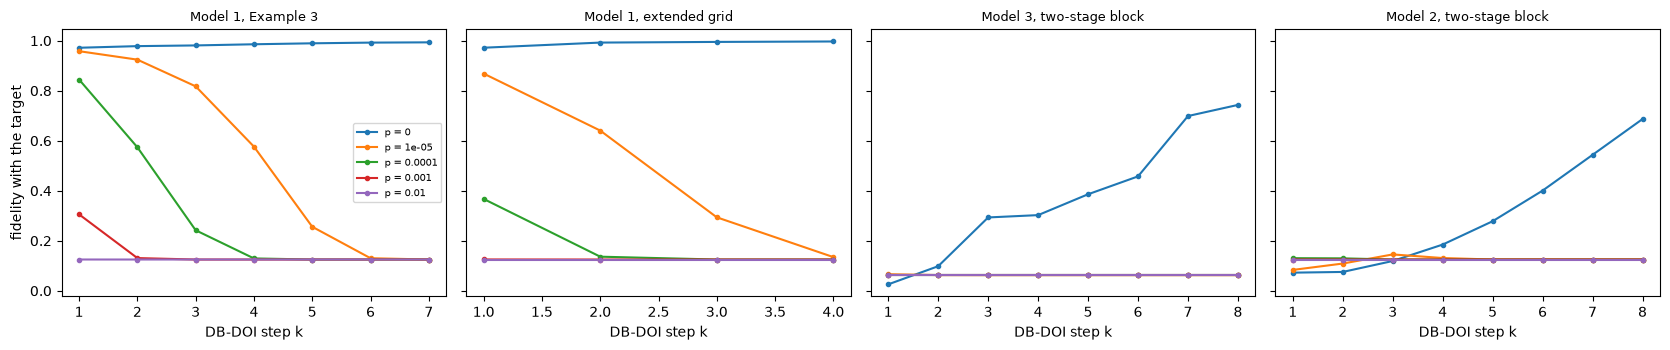

In [4]:
print("global-depolarizing estimate against the simulation, at the step with the largest noiseless fidelity:")
for name, r in results.items():
    k = max(range(len(r["cnot"])), key=lambda k: r["runs"][0.0][k]["fidelity"])
    f0, n = r["runs"][0.0][k]["fidelity"], r["cnot"][k]
    for p in P_VALUES[1:]:
        estimate = f0 * (1 - p) ** n + (1 - (1 - p) ** n) * r["g"] / 16
        print(f"   {name}, k={k + 1} ({n:.3g} CNOTs), p={p:g}: simulated F = {r['runs'][p][k]['fidelity']:.4f}, estimate {estimate:.4f}")

with open("simulation_results/Er_LiYF4_compiled_DB_DOI_L_9.pickle", "rb") as file:
    er2 = pickle.load(file)
budget = [
    ("Model 1, Example 3, k = 6 (1 - F < 1e-2)", 364 * ce["oracle_cnot"]),
    ("Model 1, extended grid, k = 2", 4 * cases["Model 1, extended grid"]["cnot_per_call"]),
    ("Model 2, DB-DOI k = 5, full 9 qubits", er2["doi_histories"][er2["ground_sector"]][5]["queries"] * er2["oracle_cnot"]),
    ("Model 3, DB-DOI k = 5, full 8 qubits", compiled14["history_full"][5]["queries"] * compiled14["oracle_cnot"]),
    ("Model 2, two-stage block, k = 8", results["Model 2, two-stage block"]["cnot"][7]),
    ("Model 3, two-stage block, k = 8", results["Model 3, two-stage block"]["cnot"][7]),
]
print(f"\n{'circuit':45s} {'CNOTs':>10s} {'p with (1-p)^N = 1/2':>22s}")
for name, n in budget:
    print(f"{name:45s} {n:10.3g} {np.log(2) / n:22.2e}")

fig, axes = plt.subplots(1, len(results), figsize=(4.2 * len(results), 3.6), sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    for p in P_VALUES:
        ax.plot(range(1, len(r["cnot"]) + 1), [x["fidelity"] for x in r["runs"][p]], "o-", ms=3, label=f"p = {p:g}")
    ax.set_title(name, fontsize=9); ax.set_xlabel("DB-DOI step k")
axes[0].set_ylabel("fidelity with the target"); axes[0].legend(fontsize=7)
plt.tight_layout()
plt.savefig("pdfs_figures/noisy_DB_DOI.pdf")
plt.show()
with open("simulation_results/noisy_DB_DOI.pickle", "wb") as file:
    pickle.dump(dict(p_values=P_VALUES, results=results, budget=budget, n_ext=n_ext, steps_ext=steps_ext), file)

#### Conclusions

- **The method is exact.** The superoperator composition reproduces qibo's noisy density-matrix simulation of the explicit circuits to all printed digits, and the noiseless compiled results of `Example_3`.
- **Longer durations pay off in CNOTs.** For Model 1, durations up to $10^2$ need 32 instead of 4 Trotter steps per oracle call, but reach $1-F<10^{-2}$ after 2 DB-DOI steps: $6.9\times10^4$ CNOTs against $7.8\times10^5$.
- **Noise.** The best fidelity with the target drops to 0.96 / 0.84 / 0.31 (Model 1, $p = 10^{-5}/10^{-4}/10^{-3}$), always at the first DB-DOI step. The two-stage block circuits of Models 2 and 3 lose their signal already at $p = 10^{-5}$.
- **Budgets.** Keeping half of the noiseless signal needs $p \lesssim 10^{-5}$ (Model 1, extended grid) and $10^{-8}$–$10^{-10}$ (Models 2 and 3). The global-depolarizing estimate behind these budgets is conservative (0.81 against 0.84 simulated for the first Model 1 step at $p = 10^{-4}$).